# CNN PIPELINE




In [2]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
paultimothymooney_chest_xray_pneumonia_path = kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia')

print('Data source import complete.')


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Data source import complete.


# 1. Importing images into dataframe

In [3]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers


DATASET = Path(paultimothymooney_chest_xray_pneumonia_path) / "chest_xray"

print("Dataset location:", DATASET)
print("Contents:", [folder.name for folder in DATASET.iterdir()])

SEED = 42
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]
ORIGINAL_SPLITS = ["train", "val", "test"]
IMAGE_EXTENSIONS = {".jpeg", ".jpg", ".png"}

# ok so the dataset already has split done, i will merge the folders images into one table
# so we can split it ourselves

rows = []

for split in ORIGINAL_SPLITS:
    for label in CLASS_NAMES:

        # like PATH BECOMES DATASET/train/NORMAL/img.jpeg etc
        folder = DATASET / split / label

        assert folder.is_dir(), f"Missing folder: {folder}"

        for image_path in sorted(folder.iterdir()):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:

                # will create rows like PATH | LABEL(NORMAL VS PNEMONIA) | TRAIN/TEST/VAL
                rows.append({
                    "path": str(image_path),
                    "label": label,
                    "original_split": split
                })

df = pd.DataFrame(rows)

print("Total images:", len(df))
display(df.head())

Dataset location: /kaggle/input/chest-xray-pneumonia/chest_xray
Contents: ['chest_xray', '__MACOSX', 'val', 'test', 'train']
Total images: 5856


,path,label,original_split
0,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train
1,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train
2,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train
3,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train
4,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,train


# 2. Check class distributions

In [4]:
tf.keras.utils.set_random_seed(SEED)


counts = pd.crosstab(
    df["original_split"],
    df["label"],
    margins=True
)

display(counts)

class_summary = df["label"].value_counts().to_frame(name="count")
class_summary["percentage"] = (class_summary["count"] / len(df) * 100).round(2)

display(class_summary)

label,NORMAL,PNEUMONIA,All
original_split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
All,1583,4273,5856


,count,percentage
label,,
PNEUMONIA,4273,72.97
NORMAL,1583,27.03


# 3. Plotting it to see visually

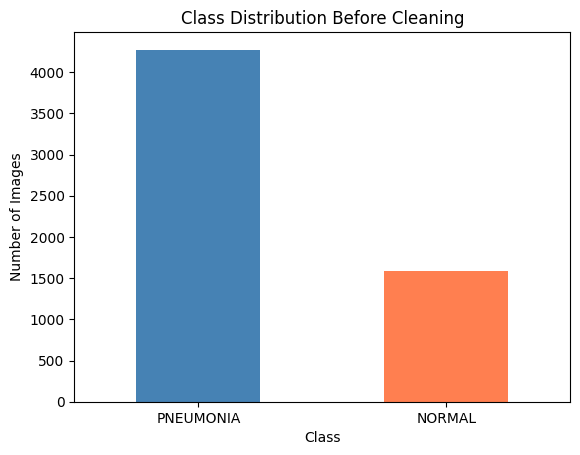

In [5]:
import matplotlib.pyplot as plt

class_summary["count"].plot(kind="bar",color=["steelblue", "coral"])

plt.title("Class Distribution Before Cleaning")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()

# 4. Inspecting image

NORMAL: size=(2090, 1858), mode=L
PNEUMONIA: size=(1152, 760), mode=L


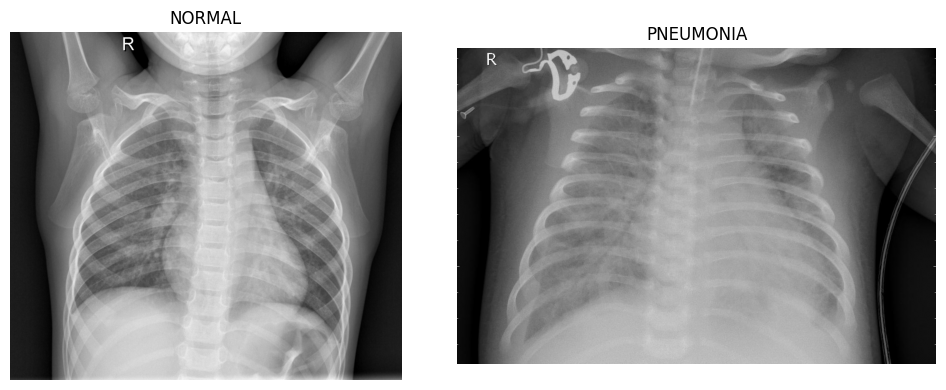

In [6]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, label in zip(axes, CLASS_NAMES):
    sample_path = df.loc[df["label"] == label, "path"].iloc[0]

    with Image.open(sample_path) as img:
        print(f"{label}: size={img.size}, mode={img.mode}")

        ax.imshow(img, cmap="gray")
        ax.set_title(label)
        ax.axis("off")

plt.tight_layout()
plt.show()

# 5. Checking duplications,corruption etc

# so mode L means grayscale images, dimensions are NORMAL: size=(2090, 1858), mode=L
# PNEUMONIA: size=(1152, 760), mode=L

# to check image duplicates, need to create hashes of each image to find duplicate.
# also creating RGB channels because to compare with pretrained model may require RGB channeling.

In [7]:
import hashlib
from PIL import UnidentifiedImageError

IMG_SIZE = (224, 224)

seen = {}
records = []
corrupted = []
duplicates = []
conflicting_hashes = set()

# PASS 1: Find readable, unique images before resizing
for row in df.to_dict("records"):
    try:
        with Image.open(row["path"]) as img:
            img.load()
            original_mode = img.mode
            width, height = img.size

            # Standardize channels before comparing pixels
            rgb = img.convert("RGB")

            fingerprint = hashlib.sha256(
                str(rgb.size).encode() + rgb.tobytes()
            ).hexdigest()

        if fingerprint in seen:
            duplicates.append(row["path"])

            if seen[fingerprint] != row["label"]:
                conflicting_hashes.add(fingerprint)

            continue

        seen[fingerprint] = row["label"]

        records.append({
            **row,
            "width": width,
            "height": height,
            "mode": original_mode,
            "image_hash": fingerprint
        })

    except (OSError, ValueError, UnidentifiedImageError) as error:
        corrupted.append({
            "path": row["path"],
            "error": str(error)
        })

# Exclude identical images that have conflicting labels
clean_df = pd.DataFrame(records)

clean_df = clean_df[
    ~clean_df["image_hash"].isin(conflicting_hashes)
].reset_index(drop=True)

assert len(clean_df) > 0, "No usable images found."

print("Original images:", len(df))
print("Corrupted images:", len(corrupted))
print("Extra duplicate copies:", len(duplicates))
print("Conflicting image groups:", len(conflicting_hashes))
print("Final usable images:", len(clean_df))

Original images: 5856
Corrupted images: 0
Extra duplicate copies: 32
Conflicting image groups: 0
Final usable images: 5824


In [ ]:
cleaning_summary = pd.DataFrame({
    "before": df["label"].value_counts(),
    "after": clean_df["label"].value_counts()
}).fillna(0).astype(int)

cleaning_summary["after_percentage"] = (100 * cleaning_summary["after"] / len(clean_df)).round(2)

display(cleaning_summary)

display(clean_df["mode"].value_counts())

display(clean_df[["width", "height"]].describe())

,before,after,after_percentage
label,,,
PNEUMONIA,4273,4245,72.89
NORMAL,1583,1579,27.11


,count
mode,
L,5541
RGB,283


,width,height
count,5824.000000,5824.000000
mean,1327.476133,970.225962
std,363.525671,383.299275
min,384.000000,127.000000
25%,1056.000000,688.000000
50%,1280.000000,886.000000
75%,1560.000000,1187.000000
max,2916.000000,2713.000000


# 6. Applying Resizing/Normalization



In [8]:
# NOW RESIZING AND NORMALIZING

X = np.empty((len(clean_df), 224, 224, 3),dtype=np.float32)

for index, path in enumerate(clean_df["path"]):
    with Image.open(path) as img:
        img = img.convert("RGB")
        img = img.resize((224, 224),Image.Resampling.BILINEAR)

        X[index] = np.asarray(img, dtype=np.float32) / 255.0

# NORMAL = 0, PNEUMONIA = 1
Y = clean_df["label"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).to_numpy(dtype=np.int32)

print("Image array:", X.shape)
print("Label array:", Y.shape)
print("Pixel range:", X.min(), "to", X.max())

Image array: (5824, 224, 224, 3)
Label array: (5824,)
Pixel range: 0.0 to 1.0


# 7. Splitting dataframe
# TRAIN TEST SPLIT 80/10/10
# splitting index is faster for computing


In [9]:

indexes = np.arange(len(Y))

# 80% training, 20% remaining
train_idx, remaining_idx = train_test_split(
    indexes,
    test_size=0.20,
    random_state=SEED,
    stratify=Y
)

# remaining 20% into 10% validation and 10% test
val_idx, test_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=Y[remaining_idx]
)

X_train, Y_train = X[train_idx], Y[train_idx]
X_val, Y_val = X[val_idx], Y[val_idx]
X_test, Y_test = X[test_idx], Y[test_idx]

split_counts = pd.DataFrame({
    "train": np.bincount(Y_train, minlength=2),
    "val": np.bincount(Y_val, minlength=2),
    "test": np.bincount(Y_test, minlength=2)
}, index=["NORMAL", "PNEUMONIA"])

display(split_counts)

,train,val,test
NORMAL,1263,158,158
PNEUMONIA,3396,424,425


In [10]:
import gc
del X
gc.collect()

30

# 8. Adding class weights
# ok so class imbalance is found,around like 27 percent is normal and 70 percent is pneomonia
# gotta use class weights here

In [11]:
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=Y_train
)

class_weights = dict(enumerate(weights))
print(class_weights)


# Approximately {0: 1.84, 1: 0.69}

{0: np.float64(1.844418052256532), 1: np.float64(0.6859540636042403)}


# 9. Checking leak

In [12]:
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

train_hashes = set(clean_df.iloc[train_idx]["image_hash"])
val_hashes = set(clean_df.iloc[val_idx]["image_hash"])
test_hashes = set(clean_df.iloc[test_idx]["image_hash"])

assert train_hashes.isdisjoint(val_hashes)
assert train_hashes.isdisjoint(test_hashes)
assert val_hashes.isdisjoint(test_hashes)

print("No shared rows or exact duplicate images across splits.")

No shared rows or exact duplicate images across splits.


# 10. Augmentation
# random rotate , zoom, translate, brightness



In [13]:
def augmentation_tuning(scheme):
    if scheme == "light":
        rotation, zoom, shift, brightness = 0.02, 0.10, 0.05, 0.10
    else:
        rotation, zoom, shift, brightness = 0.04, 0.15, 0.08, 0.15

    return models.Sequential([
        layers.RandomRotation(
            rotation, fill_mode="reflect", seed=SEED
        ),
        layers.RandomZoom(
            height_factor=(-zoom, zoom),
            width_factor=None,
            fill_mode="reflect",
            seed=SEED + 1
        ),
        layers.RandomTranslation(
            shift, shift,
            fill_mode="reflect",
            seed=SEED + 2
        ),
        layers.RandomBrightness(
            brightness,
            value_range=(0, 1),
            seed=SEED + 3
        )
    ],name="augmentation")


# 11. Before vs after Augmentation

Rotation, zoom, translation, and brightness augmentation are applied only during training. Validation and test images are not augmented. The before/after visualization explicitly activates augmentation for demonstration.

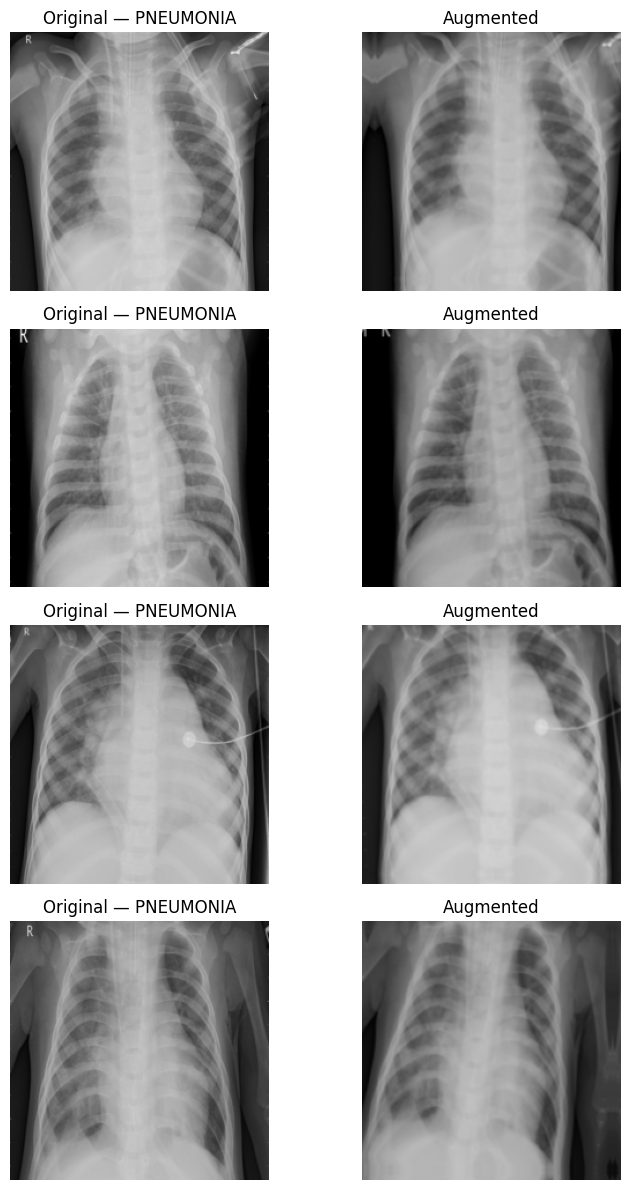

In [14]:
# for demonstration purposes

rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(X_train), size=4, replace=False)

originals = X_train[sample_indices]

preview_augmentation = augmentation_tuning("light")
augmented = preview_augmentation(originals, training=True).numpy()

fig, axes = plt.subplots(4, 2, figsize=(8, 12))

for row, index in enumerate(sample_indices):
    label = "NORMAL" if Y_train[index] == 0 else "PNEUMONIA"

    axes[row, 0].imshow(originals[row])
    axes[row, 0].set_title(f"Original — {label}")

    axes[row, 1].imshow(augmented[row])
    axes[row, 1].set_title("Augmented")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

# 12. TRAINING PIPELINE

In [15]:
# lets train

def build_model(hyper_param):
    model_layers = [
        layers.Input(shape=(224, 224, 3)),
        augmentation_tuning(hyper_param["augmentation"])
    ]

    if hyper_param["normalization"] == "two_x_minus_one":
        model_layers.append(layers.Rescaling(scale=2.0, offset=-1.0))

    model_layers.extend([
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.Flatten(),

        layers.Dense(
            64,
            activation="relu",
            kernel_regularizer=regularizers.l2(hyper_param["l2_lambda"])
        ),
        layers.Dropout(hyper_param["dropout"]),
        layers.Dense(1, activation="sigmoid")
    ])

    cnn = models.Sequential(model_layers)

    cnn.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hyper_param["learning_rate"]
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    return cnn


# 13. Early stopping, and loss func etc

In [16]:
from google.colab import drive
drive.mount("/content/drive")

OUTPUT = Path("/content/drive/MyDrive/chest_xray/tuning")
OUTPUT.mkdir(parents=True, exist_ok=True)

def start_tuning(hyper_param, X_fit, Y_fit, run_name):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)

    cnn = build_model(hyper_param)

    classes = np.unique(Y_fit)
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=Y_fit
    )
    trial_weights = dict(zip(classes.tolist(), weights.tolist()))

    checkpoint_path = OUTPUT / f"{run_name}.keras"

    trial_callbacks = [
        callbacks.ModelCheckpoint(
            str(checkpoint_path),
            monitor="val_auc",
            mode="max",
            save_best_only=True
        ),
        callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=hyper_param["patience"],
            restore_best_weights=True
        )
    ]

    history = cnn.fit(
        X_fit,
        Y_fit,
        validation_data=(X_val, Y_val),
        epochs=hyper_param["epochs"],
        batch_size=hyper_param["batch_size"],
        class_weight=trial_weights,
        callbacks=trial_callbacks,
        shuffle=True,
        verbose=2
    )

    scores = cnn.evaluate(
        X_val, Y_val,
        batch_size=hyper_param["batch_size"],
        return_dict=True,
        verbose=0
    )

    with open(OUTPUT / f"{run_name}_history.json", "w") as file:
        json.dump(history.history, file)

    result = {
        **hyper_param,
        "run": run_name,
        "epochs_run": len(history.history["loss"]),
        "best_epoch": int(np.argmax(history.history["val_auc"]) + 1),
        "val_accuracy": scores["accuracy"],
        "val_auc": scores["auc"],
        "val_loss": scores["loss"],
        "model_path": str(checkpoint_path)
    }

    del cnn
    gc.collect()

    return result

Mounted at /content/drive


In [ ]:
clean_df.to_csv(OUTPUT / "clean_dataset.csv", index=False)
np.savez(OUTPUT / "split_indices.npz", train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)
pd.DataFrame(corrupted).to_csv(OUTPUT / "corrupted_images.csv", index=False)
pd.DataFrame({"path": duplicates}).to_csv(OUTPUT / "duplicate_copies.csv", index=False)
cleaning_summary.to_csv(OUTPUT / "cleaning_summary.csv")
split_counts.to_csv(OUTPUT / "split_counts.csv")

# 14. GRID SEARCH

initially i was doing all 256 combinations , but it is time and resource intensive, better approach is randomnly pick 30 hyperparameters from 256 combinations and see which one is better

In [17]:
from sklearn.model_selection import ParameterSampler
from sklearn.utils.class_weight import compute_class_weight
import json
import gc

hyper_parameters = {
    "batch_size": [32, 64],
    "learning_rate": [0.001, 0.0001],
    "epochs": [15, 30],
    "dropout": [0.3, 0.5],
    "patience": [3, 5],
    "l2_lambda": [0.0001, 0.001],
    "normalization": ["zero_one", "two_x_minus_one"], # [0-1],[2*x-1]
    "augmentation": ["light", "strong"]
}

combinations = list(ParameterSampler(hyper_parameters,n_iter=30,random_state=SEED))
print("Total runs:", len(combinations))  # 30

Total runs: 30


In [ ]:
check_parameters = {**combinations[0], "epochs": 1}
check_result = start_tuning(check_parameters, X_train, Y_train, "code_check")
print(check_result)

73/73 - 20s - 278ms/step - accuracy: 0.5750 - auc: 0.7117 - loss: 0.6503 - val_accuracy: 0.8368 - val_auc: 0.9307 - val_loss: 0.4958
{'patience': 3, 'normalization': 'zero_one', 'learning_rate': 0.0001, 'l2_lambda': 0.0001, 'epochs': 1, 'dropout': 0.5, 'batch_size': 64, 'augmentation': 'strong', 'run': 'code_check', 'epochs_run': 1, 'best_epoch': 1, 'val_accuracy': 0.8367697596549988, 'val_auc': 0.9307454824447632, 'val_loss': 0.49583014845848083, 'model_path': '/content/drive/MyDrive/chest_xray/tuning/code_check.keras'}


In [18]:
# Avoid mixing resumed results with another grid, architecture, or split.
search_manifest = {
    "search_method": "random",
    "sampled_combinations": combinations,
    "grid": hyper_parameters,
    "seed": SEED,
    "architecture": "conv32_pool_conv64_pool_conv128_pool_flatten_dense64_sigmoid",
    "selection_metric": "val_auc",
    "train_hashes": clean_df.iloc[train_idx]["image_hash"].tolist(),
    "validation_hashes": clean_df.iloc[val_idx]["image_hash"].tolist(),
    "test_hashes": clean_df.iloc[test_idx]["image_hash"].tolist()
}
manifest_path = OUTPUT / "search_manifest.json"
if manifest_path.exists():
    with open(manifest_path) as file:
        previous_manifest = json.load(file)
    if previous_manifest != search_manifest:
        raise ValueError("Search configuration changed. Use a new OUTPUT folder.")
else:
    if (OUTPUT / "grid_results.csv").exists():
        raise ValueError("Existing results have no manifest. Use a new OUTPUT folder to avoid mixing runs.")
    with open(manifest_path, "w") as file:
        json.dump(search_manifest, file, indent=2)

# 15. Launch grid search

In [20]:
results_path = OUTPUT / "grid_results.csv"

if results_path.exists():
    results = pd.read_csv(results_path).to_dict("records")
else:
    results = []

completed = {row["run"] for row in results}

for number, p in enumerate(combinations):
    run_name = f"grid_{number:03d}"

    if run_name in completed:
        continue

    print(f"\nExperiment {number + 1}/{len(combinations)}")
    print(p)

    result = start_tuning(p, X_train, Y_train, run_name)
    results.append(result)

    pd.DataFrame(results).to_csv(results_path, index=False)

results_df = pd.DataFrame(results)
display(results_df.sort_values("val_auc", ascending=False).head())

,patience,normalization,learning_rate,l2_lambda,epochs,dropout,batch_size,augmentation,run,epochs_run,best_epoch,val_accuracy,val_auc,val_loss,model_path
21,5,two_x_minus_one,0.0010,0.0001,30,0.3,32,light,grid_021,19,14,0.957045,0.995313,0.133246,/content/drive/MyDrive/chest_xray/tuning/grid_...
1,3,two_x_minus_one,0.0001,0.0001,15,0.3,32,light,grid_001,15,15,0.948454,0.993992,0.119586,/content/drive/MyDrive/chest_xray/tuning/grid_...
17,5,two_x_minus_one,0.0001,0.0010,15,0.3,32,light,grid_017,14,9,0.948454,0.993231,0.148226,/content/drive/MyDrive/chest_xray/tuning/grid_...
24,5,zero_one,0.0010,0.0001,15,0.5,32,light,grid_024,12,7,0.960481,0.993178,0.136388,/content/drive/MyDrive/chest_xray/tuning/grid_...
9,3,two_x_minus_one,0.0001,0.0010,30,0.3,32,light,grid_009,13,10,0.958763,0.993081,0.141022,/content/drive/MyDrive/chest_xray/tuning/grid_...


In [ ]:
results_path = OUTPUT / "grid_results.csv"

if results_path.exists():
    results = pd.read_csv(results_path).to_dict("records")
else:
    results = []

completed = {row["run"] for row in results}

for number, p in enumerate(combinations):
    run_name = f"grid_{number:03d}"

    if run_name in completed:
        continue

    print(f"\nExperiment {number + 1}/{len(combinations)}")
    print(p)

    result = start_tuning(p, X_train, Y_train, run_name)
    results.append(result)

    pd.DataFrame(results).to_csv(results_path, index=False)

results_df = pd.DataFrame(results)
display(results_df.sort_values("val_auc", ascending=False).head())


Experiment 1/30
{'patience': 3, 'normalization': 'zero_one', 'learning_rate': 0.0001, 'l2_lambda': 0.0001, 'epochs': 15, 'dropout': 0.5, 'batch_size': 64, 'augmentation': 'strong'}
Epoch 1/15
73/73 - 13s - 174ms/step - accuracy: 0.5737 - auc: 0.7110 - loss: 0.6503 - val_accuracy: 0.8419 - val_auc: 0.9301 - val_loss: 0.4941
Epoch 2/15
73/73 - 9s - 122ms/step - accuracy: 0.7856 - auc: 0.8782 - loss: 0.4733 - val_accuracy: 0.8797 - val_auc: 0.9617 - val_loss: 0.3137
Epoch 3/15
73/73 - 9s - 126ms/step - accuracy: 0.8450 - auc: 0.9178 - loss: 0.3822 - val_accuracy: 0.8110 - val_auc: 0.9702 - val_loss: 0.4703
Epoch 4/15
73/73 - 9s - 121ms/step - accuracy: 0.8674 - auc: 0.9348 - loss: 0.3399 - val_accuracy: 0.8333 - val_auc: 0.9736 - val_loss: 0.4351
Epoch 5/15
73/73 - 11s - 150ms/step - accuracy: 0.8832 - auc: 0.9455 - loss: 0.3085 - val_accuracy: 0.7904 - val_auc: 0.9754 - val_loss: 0.5153
Epoch 6/15
73/73 - 9s - 123ms/step - accuracy: 0.8789 - auc: 0.9488 - loss: 0.2986 - val_accuracy: 0.

,patience,normalization,learning_rate,l2_lambda,epochs,dropout,batch_size,augmentation,run,epochs_run,best_epoch,val_accuracy,val_auc,val_loss,model_path
21,5,two_x_minus_one,0.0010,0.0001,30,0.3,32,light,grid_021,19,14,0.957045,0.995313,0.133246,/content/drive/MyDrive/chest_xray/tuning/grid_...
1,3,two_x_minus_one,0.0001,0.0001,15,0.3,32,light,grid_001,15,15,0.948454,0.993992,0.119586,/content/drive/MyDrive/chest_xray/tuning/grid_...
17,5,two_x_minus_one,0.0001,0.0010,15,0.3,32,light,grid_017,14,9,0.948454,0.993231,0.148226,/content/drive/MyDrive/chest_xray/tuning/grid_...
24,5,zero_one,0.0010,0.0001,15,0.5,32,light,grid_024,12,7,0.960481,0.993178,0.136388,/content/drive/MyDrive/chest_xray/tuning/grid_...
9,3,two_x_minus_one,0.0001,0.0010,30,0.3,32,light,grid_009,13,10,0.958763,0.993081,0.141022,/content/drive/MyDrive/chest_xray/tuning/grid_...


# 16. Generate hyper parameter table

In [21]:
best_row = results_df.sort_values(
    ["val_auc", "run"],
    ascending=[False, True]
).iloc[0]

# Recover original Python parameter types from the grid
best_number = int(best_row["run"].split("_")[-1])
best_parameters = combinations[best_number]

parameter_table = pd.DataFrame([
    {
        "Hyperparameter": name,
        "Range searched": str(values),
        "Best value found": best_parameters[name]
    }
    for name, values in hyper_parameters.items()
])

display(parameter_table)

parameter_table.to_csv(
    OUTPUT / "hyperparameter_table.csv",
    index=False
)

,Hyperparameter,Range searched,Best value found
0,batch_size,"[32, 64]",32
1,learning_rate,"[0.001, 0.0001]",0.001
2,epochs,"[15, 30]",30
3,dropout,"[0.3, 0.5]",0.3
4,patience,"[3, 5]",5
5,l2_lambda,"[0.0001, 0.001]",0.0001
6,normalization,"['zero_one', 'two_x_minus_one']",two_x_minus_one
7,augmentation,"['light', 'strong']",light


Completed grid trials: 30 / 30


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     6,422,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,547,717 (74.57 MB)

 Trainable params: 6,515,905 (24.86 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 13,031,812 (49.71 MB)

,Layer,Type,Output shape,Parameters
0,augmentation,Sequential,"(None, 224, 224, 3)",0
1,rescaling,Rescaling,"(None, 224, 224, 3)",0
2,conv2d,Conv2D,"(None, 224, 224, 32)",896
3,max_pooling2d,MaxPooling2D,"(None, 112, 112, 32)",0
4,conv2d_1,Conv2D,"(None, 112, 112, 64)",18496
5,max_pooling2d_1,MaxPooling2D,"(None, 56, 56, 64)",0
6,conv2d_2,Conv2D,"(None, 56, 56, 128)",73856
7,max_pooling2d_2,MaxPooling2D,"(None, 28, 28, 128)",0
8,flatten,Flatten,"(None, 100352)",0
9,dense,Dense,"(None, 64)",6422592


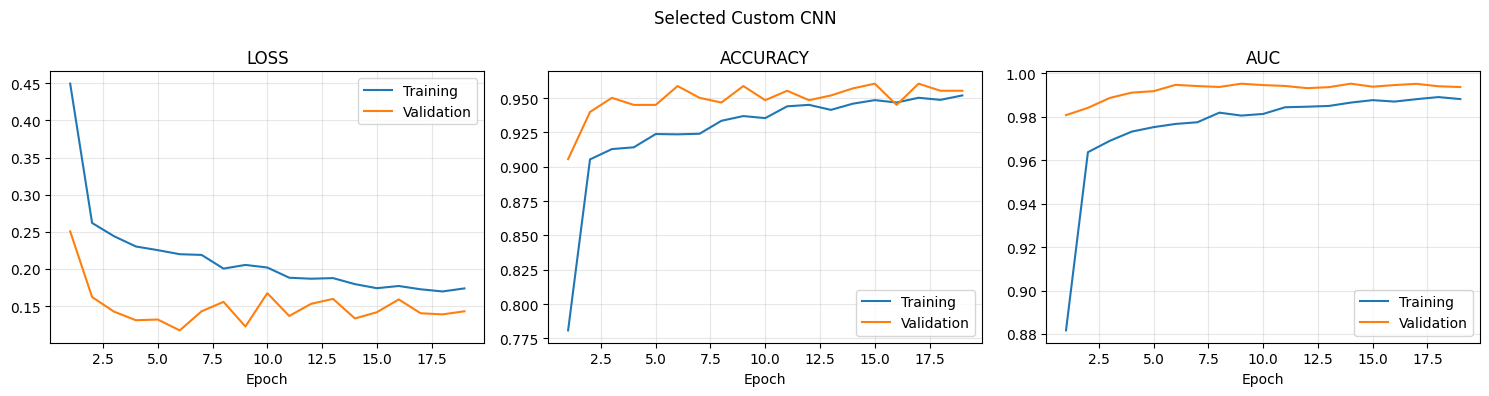

In [22]:
print(f"Completed grid trials: {len(results_df)} / {len(combinations)}")
best_model = tf.keras.models.load_model(best_row["model_path"])
best_model.summary()
layer_table = pd.DataFrame([
    {"Layer": layer.name, "Type": type(layer).__name__,
     "Output shape": str(tuple(layer.output.shape)), "Parameters": layer.count_params()}
    for layer in best_model.layers
])
display(layer_table)
layer_table.to_csv(OUTPUT / "custom_cnn_layer_table.csv", index=False)
del best_model
gc.collect()


def plot_history(run_name, title):
    with open(OUTPUT / f"{run_name}_history.json") as file:
        training_history = json.load(file)
    epochs = np.arange(1, len(training_history["loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric in zip(axes, ["loss", "accuracy", "auc"]):
        ax.plot(epochs, training_history[metric], label="Training")
        ax.plot(epochs, training_history[f"val_{metric}"], label="Validation")
        ax.set_title(metric.upper())
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUTPUT / f"{run_name}_curves.png", dpi=150, bbox_inches="tight")
    plt.show()

plot_history(best_row["run"], "Selected Custom CNN")

# 17. Retrain 25/50/75/100 percent of training data

In [23]:
import gc
import json

# Remove leftover full-image copies.
for name in ["X", "X_subset", "Y_subset"]:
    globals().pop(name, None)

gc.collect()


def make_volume_batches(images, labels, indices, batch_size, shuffle=False):
    batch_rng = np.random.default_rng(SEED)

    def generate():
        order = indices.copy()

        if shuffle:
            batch_rng.shuffle(order)

        for start in range(0, len(order), batch_size):
            ids = order[start:start + batch_size]

            # Only this batch is copied into memory.
            yield (
                images[ids],
                labels[ids].astype(np.float32).reshape(-1, 1)
            )

    dataset = tf.data.Dataset.from_generator(
        generate,
        output_signature=(
            tf.TensorSpec((None, *images.shape[1:]), tf.float32),
            tf.TensorSpec((None, 1), tf.float32)
        )
    )

    batches = (len(indices) + batch_size - 1) // batch_size
    return dataset.apply(
        tf.data.experimental.assert_cardinality(batches)
    )


rng = np.random.default_rng(SEED)

class_indices = {
    label: rng.permutation(np.flatnonzero(Y_train == label))
    for label in np.unique(Y_train)
}

volume_results = []

for percentage in [25, 50, 75, 100]:
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)

    selected = np.concatenate([
        indices[:max(1, int(len(indices) * percentage / 100))]
        for indices in class_indices.values()
    ])
    rng.shuffle(selected)

    print(f"\nTraining with {percentage}%: {len(selected)} images")

    batch_size = best_parameters["batch_size"]
    run_name = f"volume_{percentage}"
    checkpoint_path = OUTPUT / f"{run_name}.keras"

    train_ds = make_volume_batches(
        X_train, Y_train, selected, batch_size, shuffle=True
    )
    val_ds = make_volume_batches(
        X_val, Y_val, np.arange(len(Y_val)), batch_size
    )

    classes = np.unique(Y_train[selected])
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=Y_train[selected]
    )
    subset_weights = dict(zip(classes.tolist(), weights.tolist()))

    cnn = build_model(best_parameters)

    trial_callbacks = [
        callbacks.ModelCheckpoint(
            str(checkpoint_path),
            monitor="val_auc",
            mode="max",
            save_best_only=True
        ),
        callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=best_parameters["patience"],
            restore_best_weights=True
        )
    ]

    history = None

    try:
        history = cnn.fit(
            train_ds,
            validation_data=val_ds,
            epochs=best_parameters["epochs"],
            class_weight=subset_weights,
            callbacks=trial_callbacks,
            verbose=1
        )

        scores = cnn.evaluate(
            val_ds, return_dict=True, verbose=0
        )

        with open(OUTPUT / f"{run_name}_history.json", "w") as file:
            json.dump(history.history, file)

        volume_results.append({
            **best_parameters,
            "training_percentage": percentage,
            "training_images": len(selected),
            "run": run_name,
            "epochs_run": len(history.history["loss"]),
            "best_epoch": int(np.argmax(history.history["val_auc"]) + 1),
            "val_accuracy": scores["accuracy"],
            "val_auc": scores["auc"],
            "val_loss": scores["loss"],
            "model_path": str(checkpoint_path)
        })

        pd.DataFrame(volume_results).to_csv(
            OUTPUT / "data_volume_results.csv",
            index=False
        )

    finally:
        del history, trial_callbacks, cnn, train_ds, val_ds, selected
        tf.keras.backend.clear_session()
        gc.collect()

volume_df = pd.DataFrame(volume_results)


Training with 25%: 1164 images
Epoch 1/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 19s 320ms/step - accuracy: 0.7620 - auc: 0.8488 - loss: 0.5124 - val_accuracy: 0.7423 - val_auc: 0.9730 - val_loss: 0.6550
Epoch 2/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.8651 - auc: 0.9428 - loss: 0.3274 - val_accuracy: 0.8574 - val_auc: 0.9818 - val_loss: 0.3584
Epoch 3/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.9124 - auc: 0.9682 - loss: 0.2521 - val_accuracy: 0.9192 - val_auc: 0.9785 - val_loss: 0.2138
Epoch 4/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - accuracy: 0.9132 - auc: 0.9695 - loss: 0.2453 - val_accuracy: 0.8625 - val_auc: 0.9829 - val_loss: 0.3378
Epoch 5/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.9149 - auc: 0.9720 - loss: 0.2378 - val_accuracy: 0.9381 - val_auc: 0.9862 - val_loss: 0.1732
Epoch 6/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 0.9115 - auc: 0.9716 - loss: 0.2394 - val_accuracy: 0.9244 - val_auc: 0.9859 - val_loss: 0.2197
Epoch 7/30
3

# 18. Plot validation performance against training-data volume:

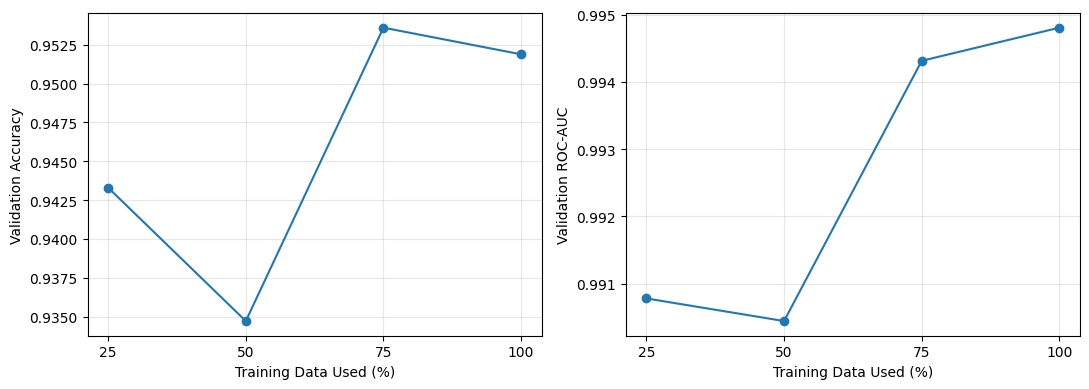

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, metric, title in [
    (axes[0], "val_accuracy", "Validation Accuracy"),
    (axes[1], "val_auc", "Validation ROC-AUC")
]:
    ax.plot(
        volume_df["training_percentage"],
        volume_df[metric],
        marker="o"
    )
    ax.set_xlabel("Training Data Used (%)")
    ax.set_ylabel(title)
    ax.set_xticks([25, 50, 75, 100])
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 19. Comparison Models

In [25]:
@tf.keras.utils.register_keras_serializable(package="ChestXray")
class CaffePreprocessing(layers.Layer):
    def call(self, inputs):
        pixels = inputs * 255.0
        bgr = tf.reverse(pixels, axis=[-1])
        means = tf.constant([103.939, 116.779, 123.68], dtype=inputs.dtype)
        return bgr - means


def compile_baseline(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                 tf.keras.metrics.AUC(name="auc")]
    )


def build_baseline(architecture):
    constructor = {"VGG16": tf.keras.applications.VGG16,
                   "ResNet50": tf.keras.applications.ResNet50}[architecture]
    backbone = constructor(weights="imagenet", include_top=False,
                           input_shape=(224, 224, 3))
    backbone.trainable = False
    inputs = layers.Input(shape=(224, 224, 3))
    features = augmentation_tuning(best_parameters["augmentation"])(inputs)
    features = CaffePreprocessing()(features)
    features = backbone(features, training=False)
    features = layers.GlobalAveragePooling2D()(features)
    features = layers.Dense(64, activation="relu",
        kernel_regularizer=regularizers.l2(best_parameters["l2_lambda"]))(features)
    features = layers.Dropout(best_parameters["dropout"])(features)
    outputs = layers.Dense(1, activation="sigmoid")(features)
    return models.Model(inputs, outputs, name=architecture), backbone


def fit_baseline_stage(model, run_name):
    checkpoint = OUTPUT / f"{run_name}.keras"
    history = model.fit(
        X_train, Y_train,
        validation_data=(X_val, Y_val),
        batch_size=best_parameters["batch_size"],
        epochs=best_parameters["epochs"],
        class_weight=class_weights, shuffle=True,
        callbacks=[
            callbacks.ModelCheckpoint(str(checkpoint), monitor="val_auc",
                                      mode="max", save_best_only=True),
            callbacks.EarlyStopping(monitor="val_auc", mode="max",
                patience=best_parameters["patience"], restore_best_weights=True)
        ], verbose=2
    )
    with open(OUTPUT / f"{run_name}_history.json", "w") as file:
        json.dump(history.history, file)
    return str(checkpoint)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/30
146/146 - 40s - 277ms/step - accuracy: 0.8555 - auc: 0.9271 - loss: 0.3676 - val_accuracy: 0.9192 - val_auc: 0.9770 - val_loss: 0.2104
Epoch 2/30
146/146 - 26s - 180ms/step - accuracy: 0.9180 - auc: 0.9715 - loss: 0.2258 - val_accuracy: 0.9278 - val_auc: 0.9822 - val_loss: 0.1705
Epoch 3/30
146/146 - 27s - 182ms/step - accuracy: 0.9302 - auc: 0.9766 - loss: 0.2036 - val_accuracy: 0.9330 - val_auc: 0.9872 - val_loss: 0.1648
Epoch 4/30
146/146 - 28s - 188ms/step - accuracy: 0.9330 - auc: 0.9803 - loss: 0.1870 - val_accuracy: 0.9519 - val_auc: 0.9877 - val_loss: 0.1456
Epoch 5/30
146/146 - 27s - 186ms/step - accuracy: 0.9384 - auc: 0.9818 - loss: 0.1798 - val_accuracy: 0.9519 - val_auc: 0.9884 - val_loss: 0.1381
Epoch 6/30
146/146 - 29s - 200ms/step - accuracy: 0.9408 - auc: 0.9831 - loss: 0.1730 - val_accuracy: 0.9536 - val_auc: 0.9892 - val_loss: 0.1367
Epoch 7/30
146/146 - 27s - 184ms/step - accuracy: 0.9395 - auc: 0.9842 - 

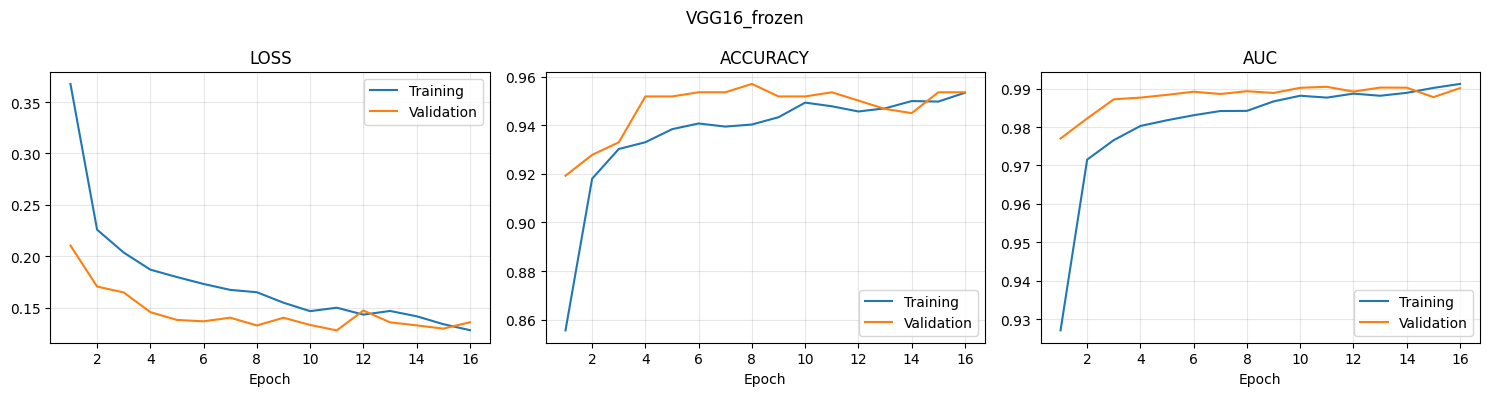

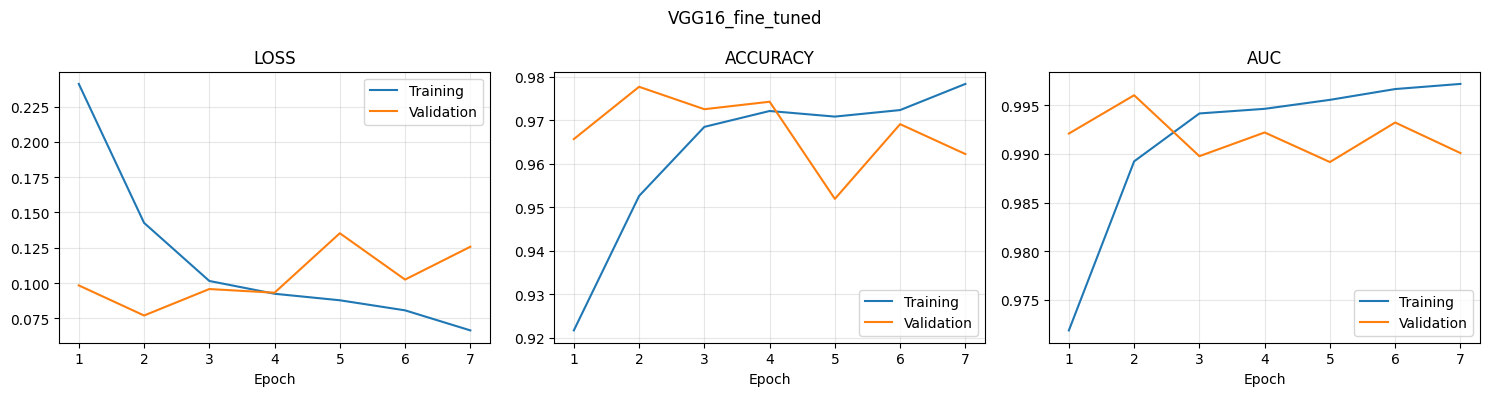

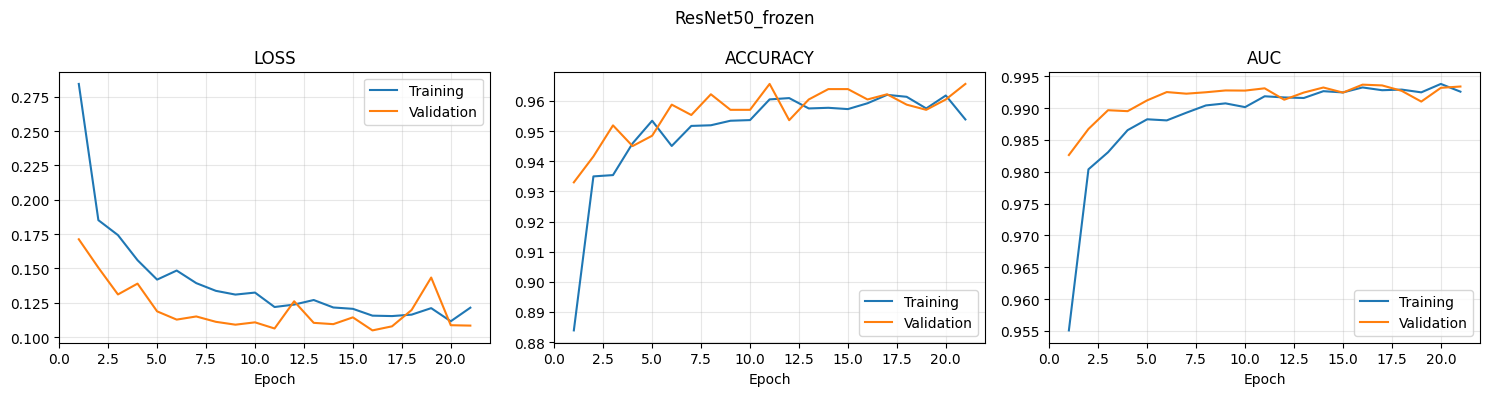

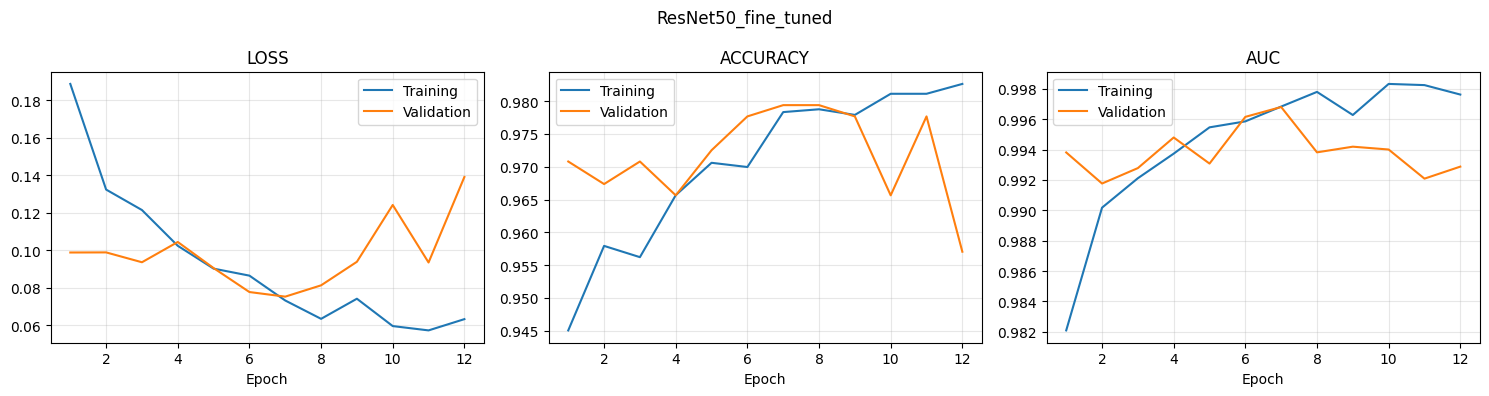

,model,stage_epochs,prior_frozen_epochs,total_epochs_executed,stage_learning_rate
0,Custom_CNN,19,0,19,0.0010
1,VGG16_frozen,16,0,16,0.0010
2,VGG16_fine_tuned,7,16,23,0.0001
3,ResNet50_frozen,21,0,21,0.0010
4,ResNet50_fine_tuned,12,21,33,0.0001


In [26]:
model_paths = {"Custom_CNN": str(best_row["model_path"])}

for architecture in ["VGG16", "ResNet50"]:
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    baseline, backbone = build_baseline(architecture)

    # Train the classifier with the pretrained backbone frozen.
    compile_baseline(baseline, best_parameters["learning_rate"])
    frozen_name = f"{architecture}_frozen"
    model_paths[frozen_name] = fit_baseline_stage(baseline, frozen_name)

    # Early stopping restored the best frozen-stage weights.
    backbone.trainable = True
    final_block = "block5_" if architecture == "VGG16" else "conv5_"
    for layer in backbone.layers:
        layer.trainable = (layer.name.startswith(final_block)
            and not isinstance(layer, layers.BatchNormalization))

    # Recompile after changing trainable layers.
    compile_baseline(baseline, best_parameters["learning_rate"] / 10)
    tuned_name = f"{architecture}_fine_tuned"
    model_paths[tuned_name] = fit_baseline_stage(baseline, tuned_name)
    with open(OUTPUT / "model_paths.json", "w") as file:
        json.dump(model_paths, file, indent=2)
    del baseline, backbone
    gc.collect()

for run_name in model_paths:
    if run_name != "Custom_CNN":
        plot_history(run_name, run_name)

protocol_rows = []
for name in model_paths:
    run = best_row["run"] if name == "Custom_CNN" else name
    with open(OUTPUT / f"{run}_history.json") as file:
        stage_history = json.load(file)
    prior_epochs = 0
    if name.endswith("_fine_tuned"):
        frozen_run = name.replace("_fine_tuned", "_frozen")
        with open(OUTPUT / f"{frozen_run}_history.json") as file:
            prior_epochs = len(json.load(file)["loss"])
    protocol_rows.append({
        "model": name, "stage_epochs": len(stage_history["loss"]),
        "prior_frozen_epochs": prior_epochs,
        "total_epochs_executed": prior_epochs + len(stage_history["loss"]),
        "stage_learning_rate": best_parameters["learning_rate"] / (10 if name.endswith("_fine_tuned") else 1)
    })
protocol_df = pd.DataFrame(protocol_rows)
display(protocol_df)
protocol_df.to_csv(OUTPUT / "comparison_training_protocol.csv", index=False)

# 20. Evaluation


Custom_CNN
              precision    recall  f1-score   support

      NORMAL     0.9018    0.9304    0.9159       158
   PNEUMONIA     0.9738    0.9624    0.9680       425

    accuracy                         0.9537       583
   macro avg     0.9378    0.9464    0.9420       583
weighted avg     0.9543    0.9537    0.9539       583



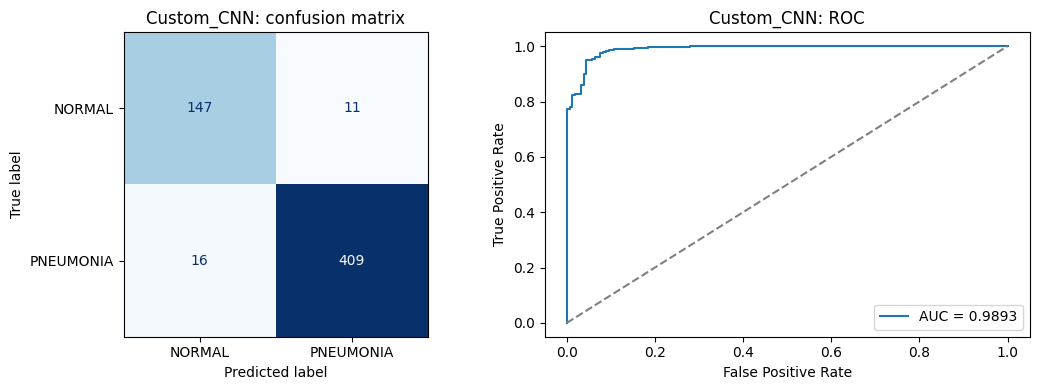


VGG16_frozen
              precision    recall  f1-score   support

      NORMAL     0.9359    0.9241    0.9299       158
   PNEUMONIA     0.9719    0.9765    0.9742       425

    accuracy                         0.9623       583
   macro avg     0.9539    0.9503    0.9521       583
weighted avg     0.9621    0.9623    0.9622       583



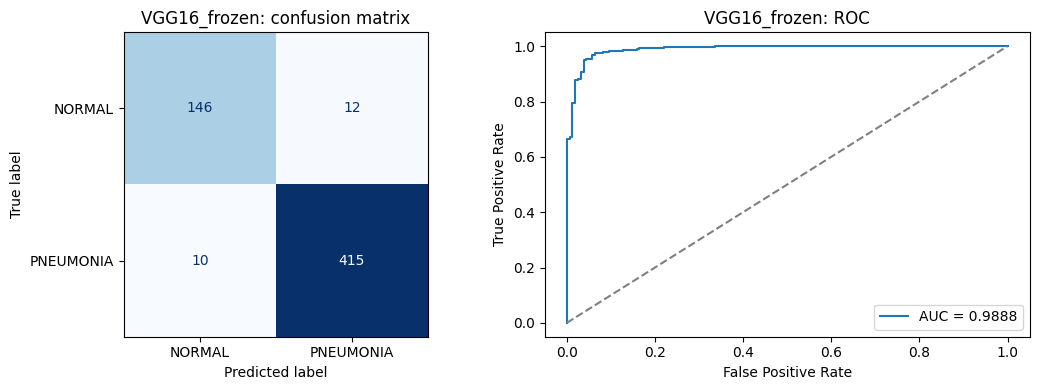


VGG16_fine_tuned
              precision    recall  f1-score   support

      NORMAL     0.9487    0.9367    0.9427       158
   PNEUMONIA     0.9766    0.9812    0.9789       425

    accuracy                         0.9691       583
   macro avg     0.9626    0.9589    0.9608       583
weighted avg     0.9690    0.9691    0.9691       583



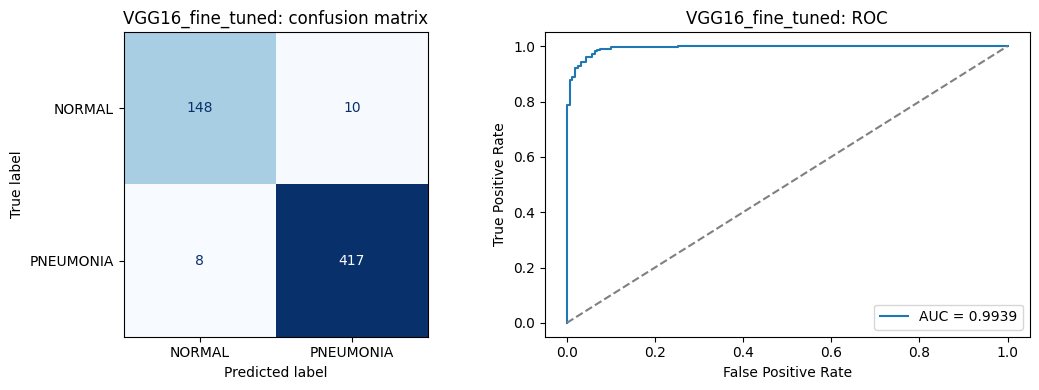


ResNet50_frozen
              precision    recall  f1-score   support

      NORMAL     0.9080    0.9367    0.9221       158
   PNEUMONIA     0.9762    0.9647    0.9704       425

    accuracy                         0.9571       583
   macro avg     0.9421    0.9507    0.9463       583
weighted avg     0.9577    0.9571    0.9573       583



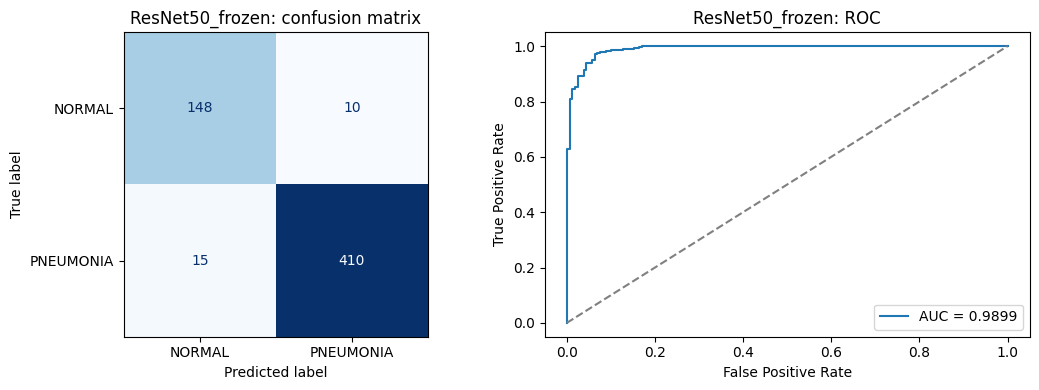


ResNet50_fine_tuned
              precision    recall  f1-score   support

      NORMAL     0.9245    0.9304    0.9274       158
   PNEUMONIA     0.9741    0.9718    0.9729       425

    accuracy                         0.9605       583
   macro avg     0.9493    0.9511    0.9502       583
weighted avg     0.9606    0.9605    0.9606       583



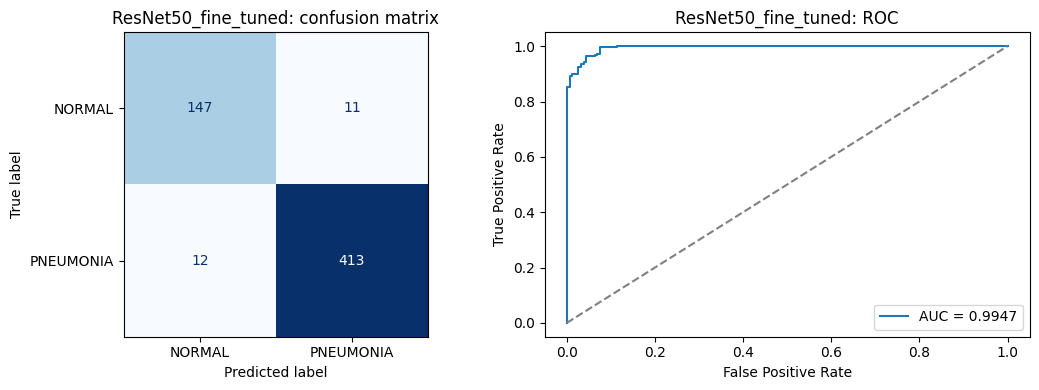

,Model,Accuracy,Macro precision,Macro recall,Macro F1,ROC-AUC
0,Custom_CNN,0.9537,0.9378,0.9464,0.9420,0.9893
1,VGG16_frozen,0.9623,0.9539,0.9503,0.9521,0.9888
2,VGG16_fine_tuned,0.9691,0.9626,0.9589,0.9608,0.9939
3,ResNet50_frozen,0.9571,0.9421,0.9507,0.9463,0.9899
4,ResNet50_fine_tuned,0.9605,0.9493,0.9511,0.9502,0.9947


In [27]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve
)

comparison_rows = []
prediction_results = {}

for model_name, model_path in model_paths.items():
    tf.keras.backend.clear_session()
    gc.collect()
    evaluated_model = tf.keras.models.load_model(model_path)
    Y_prob = evaluated_model.predict(X_test, batch_size=32, verbose=0).ravel()
    Y_pred = (Y_prob >= 0.5).astype(int)
    report = classification_report(Y_test, Y_pred, labels=[0, 1],
        target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    print(f"\n{model_name}")
    print(classification_report(Y_test, Y_pred, labels=[0, 1],
        target_names=CLASS_NAMES, digits=4, zero_division=0))
    auc = roc_auc_score(Y_test, Y_prob)
    comparison_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(Y_test, Y_pred),
        "Macro precision": report["macro avg"]["precision"],
        "Macro recall": report["macro avg"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"], "ROC-AUC": auc
    })
    prediction_results[model_name] = {"probabilities": Y_prob, "predictions": Y_pred}
    pd.DataFrame({
        "path": clean_df.iloc[test_idx]["path"].to_numpy(),
        "actual_label": Y_test, "predicted_label": Y_pred,
        "pneumonia_score": Y_prob
    }).to_csv(OUTPUT / f"{model_name}_predictions.csv", index=False)
    pd.DataFrame(report).T.to_csv(OUTPUT / f"{model_name}_report.csv")
    cm = confusion_matrix(Y_test, Y_pred, labels=[0, 1])
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        OUTPUT / f"{model_name}_confusion_matrix.csv")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
    axes[0].set_title(f"{model_name}: confusion matrix")
    fpr, tpr, _ = roc_curve(Y_test, Y_prob)
    axes[1].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    axes[1].plot([0, 1], [0, 1], "--", color="gray")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title(f"{model_name}: ROC")
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(OUTPUT / f"{model_name}_evaluation.png", dpi=150, bbox_inches="tight")
    plt.show()
    del evaluated_model
    gc.collect()

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))
comparison_df.to_csv(OUTPUT / "model_comparison.csv", index=False)

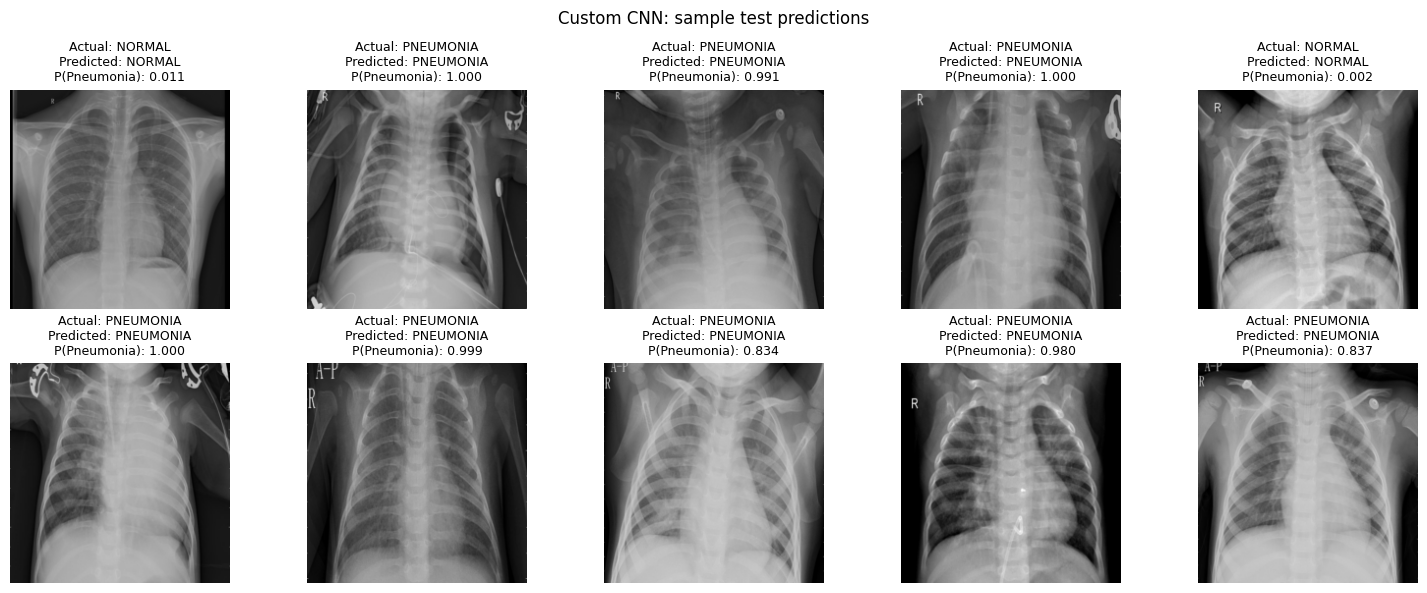

In [29]:
custom_prob = prediction_results["Custom_CNN"]["probabilities"]
custom_pred = prediction_results["Custom_CNN"]["predictions"]


def show_predictions(indices, title, filename):
    indices = np.asarray(indices)
    if len(indices) == 0:
        print("No images to display.")
        return
    columns = 5
    rows = int(np.ceil(len(indices) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(15, 3 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, index in zip(axes.flat, indices):
        ax.imshow(X_test[index])
        ax.set_title(
            f"Actual: {CLASS_NAMES[int(Y_test[index])]}\n"
            f"Predicted: {CLASS_NAMES[int(custom_pred[index])]}\n"
            f"P(Pneumonia): {custom_prob[index]:.3f}", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUTPUT / filename, dpi=150, bbox_inches="tight")
    plt.show()

rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(Y_test), size=min(10, len(Y_test)), replace=False)
show_predictions(sample_indices, "Custom CNN: sample test predictions", "sample_predictions.png")

21. Error Analysis

Normal predicted as Pneumonia: 11
Pneumonia predicted as Normal: 16
Total errors: 27


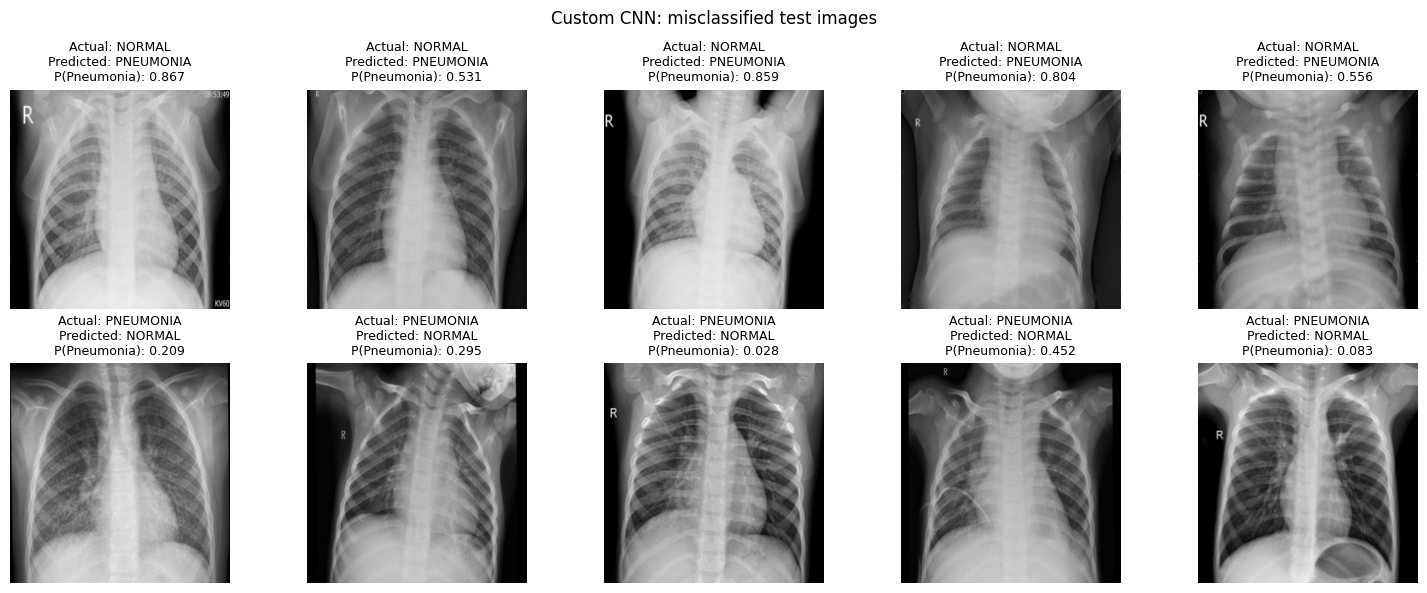

,path,actual,predicted,pneumonia_score,visual_observation,possible_explanation
0,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,PNEUMONIA,0.866553,,
1,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,PNEUMONIA,0.531240,,
2,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,PNEUMONIA,0.859036,,
3,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,PNEUMONIA,0.803947,,
4,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL,PNEUMONIA,0.555926,,
5,/kaggle/input/chest-xray-pneumonia/chest_xray/...,PNEUMONIA,NORMAL,0.209254,,
6,/kaggle/input/chest-xray-pneumonia/chest_xray/...,PNEUMONIA,NORMAL,0.294782,,
7,/kaggle/input/chest-xray-pneumonia/chest_xray/...,PNEUMONIA,NORMAL,0.027891,,
8,/kaggle/input/chest-xray-pneumonia/chest_xray/...,PNEUMONIA,NORMAL,0.452351,,
9,/kaggle/input/chest-xray-pneumonia/chest_xray/...,PNEUMONIA,NORMAL,0.082820,,


In [30]:
false_positive_idx = np.flatnonzero((Y_test == 0) & (custom_pred == 1))
false_negative_idx = np.flatnonzero((Y_test == 1) & (custom_pred == 0))
wrong_idx = np.flatnonzero(Y_test != custom_pred)
print("Normal predicted as Pneumonia:", len(false_positive_idx))
print("Pneumonia predicted as Normal:", len(false_negative_idx))
print("Total errors:", len(wrong_idx))
rng = np.random.default_rng(SEED)
selected_errors = np.concatenate([
    rng.permutation(false_positive_idx)[:5],
    rng.permutation(false_negative_idx)[:5]
])
remaining_errors = np.setdiff1d(wrong_idx, selected_errors)
selected_errors = np.concatenate([
    selected_errors,
    rng.permutation(remaining_errors)[:max(0, 10 - len(selected_errors))]
])
show_predictions(selected_errors, "Custom CNN: misclassified test images", "misclassified_images.png")
error_review = pd.DataFrame({
    "path": clean_df.iloc[test_idx[selected_errors]]["path"].to_numpy(),
    "actual": [CLASS_NAMES[int(Y_test[i])] for i in selected_errors],
    "predicted": [CLASS_NAMES[int(custom_pred[i])] for i in selected_errors],
    "pneumonia_score": custom_prob[selected_errors],
    "visual_observation": "", "possible_explanation": ""
})
display(error_review)
# Preserve observations if you have already filled the review file.
review_path = OUTPUT / "error_review.csv"
if not review_path.exists():
    error_review.to_csv(review_path, index=False)
else:
    print("Existing error_review.csv preserved; review the displayed selection separately.")
if len(wrong_idx) < 10:
    print("Fewer than 10 test errors: report all available errors. Do not manufacture errors.")